

##3.1 Business Understanding
The objective is to predict the Average Daily Rate (ADR) of hotel bookings.

Accurate ADR prediction helps hotel managers:

- Optimize pricing strategies.
- Forecast revenue.
- Improve occupancy planning.
- Support revenue management decisions.

Target variable:

ADR (Average Daily Rate)



In [ ]:
#Import libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [ ]:
df = pd.read_csv("hotel_bookings_cleaned 1.csv")

In [ ]:
#Feature Selection
y = df['adr']
X = df[['hotel','reserved_room_type','meal','lead_time','total_guests','total_nights','market_segment','previous_cancellations']]

In [ ]:
#Identify Categorical and Numerical Features
categorical_features = ['hotel','reserved_room_type','meal','market_segment']
numerical_features = ['lead_time','total_guests','total_nights','previous_cancellations']

In [ ]:
#Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
#Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ]
)

##Model 1 – Linear Regression

In [ ]:
lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("RMSE:", rmse_lr)
print("MAE:", mae_lr)
print("R²:", r2_lr)

RMSE: 0.7374978648861183
MAE: 0.5324857772268486
R²: 0.39263057218403763


##Model 2 - Decision Tree Regressor

In [ ]:
dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', DecisionTreeRegressor(random_state=42))
])

dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
mae_dt = mean_absolute_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)
print("RMSE:", rmse_dt)
print("MAE:", mae_dt)
print("R²:", r2_dt)

RMSE: 0.7510174336152902
MAE: 0.43277463233409214
R²: 0.37015827168709015


##Model 3 – Random Forest Regressor

In [ ]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=42))
])
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)
print("RMSE:", rmse_rf)
print("MAE:", mae_rf)
print("R²:", r2_rf)

RMSE: 0.6632679650145478
MAE: 0.40313953260790697
R²: 0.5087422249277449


In [ ]:
#Compare Models
results = pd.DataFrame({
    'Model':[
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],

    'RMSE':[
        rmse_lr,
        rmse_dt,
        rmse_rf
    ],

    'MAE':[
        mae_lr,
        mae_dt,
        mae_rf
    ],

    'R² Score':[
        r2_lr,
        r2_dt,
        r2_rf
    ]
})

print(results)

               Model      RMSE       MAE  R² Score
0  Linear Regression  0.737498  0.532486  0.392631
1      Decision Tree  0.751017  0.432775  0.370158
2      Random Forest  0.663268  0.403140  0.508742


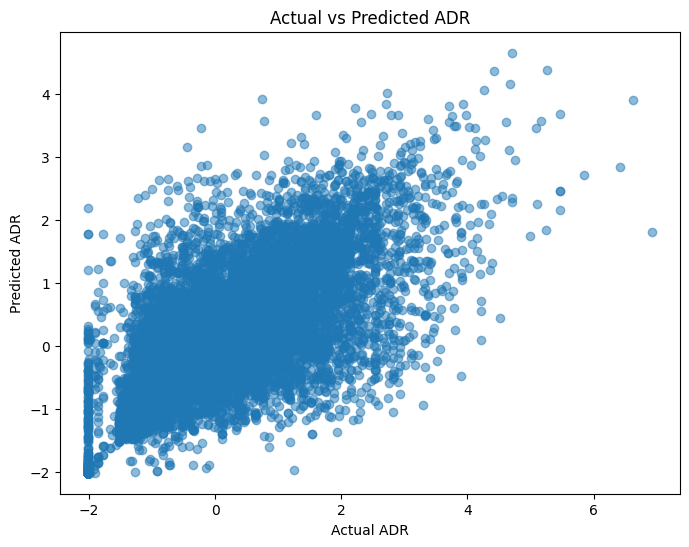

In [ ]:
#Actual vs Predicted Plot
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred_rf, alpha=0.5)

plt.xlabel("Actual ADR")
plt.ylabel("Predicted ADR")

plt.title("Actual vs Predicted ADR")

plt.show()

#### Evaluation and Reporting

Three regression models were developed to predict ADR:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor

Model performance was evaluated using:

- Root Mean Squared Error (RMSE)
- Mean Absolute Error (MAE)
- R² Score

Among the three models, Random Forest Regressor achieved the highest R² score and the lowest prediction errors, indicating superior predictive performance.

#### Business Insights

The Random Forest Regressor provided the most accurate ADR predictions.

Accurate ADR forecasting enables hotel managers to:

- Optimize pricing strategies.
- Improve revenue forecasting.
- Support occupancy planning.
- Increase profitability through better pricing decisions.

These insights help hotel management make informed operational and financial decisions.